In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

In [24]:
df = pd.read_csv("../Churn_Modelling.csv")
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Dataset Shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender   Age  \
0          1    15634602  Hargrave          619    France  Female  42.0   
1          2    15647311      Hill          608     Spain  Female  41.0   
2          3    15619304      Onio          502    France  Female  42.0   
3          4    15701354      Boni          699    France  Female  39.0   
4          5    15737888  Mitchell          850     Spain  Female  43.0   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3        

In [3]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

print(df.isnull().sum()) 

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


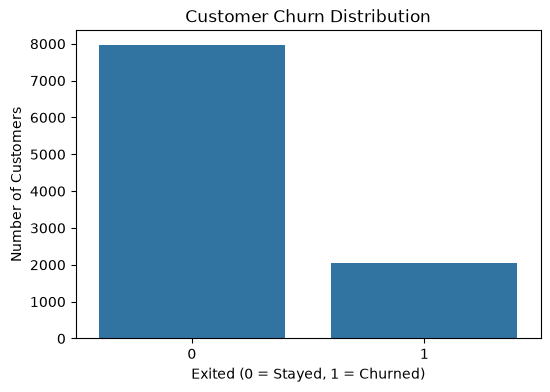

Exited
0    7963
1    2037
Name: count, dtype: int64


In [4]:
plt.figure(figsize=(6,4))
sns.countplot(x="Exited", data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

print(df["Exited"].value_counts())

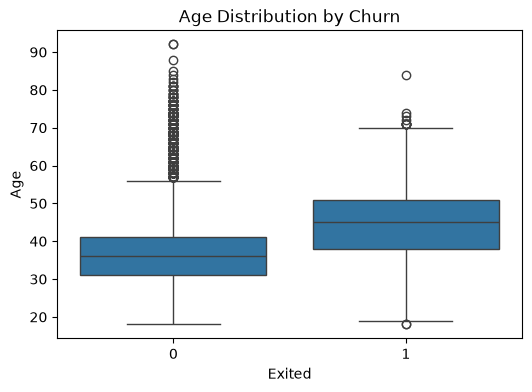

In [5]:
plt.figure(figsize=(6,4))
sns.boxplot(x="Exited", y="Age", data=df)
plt.title("Age Distribution by Churn")
plt.xlabel("Exited")
plt.ylabel("Age")
plt.show()

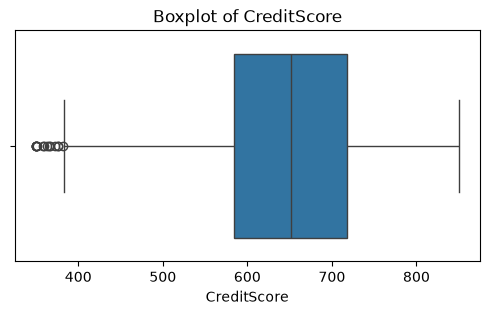

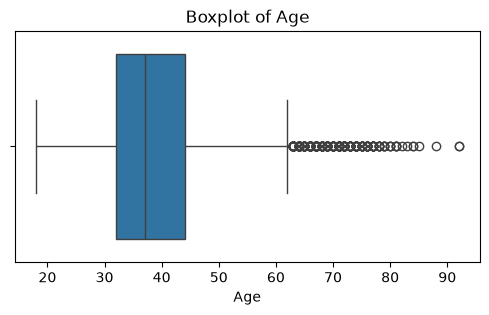

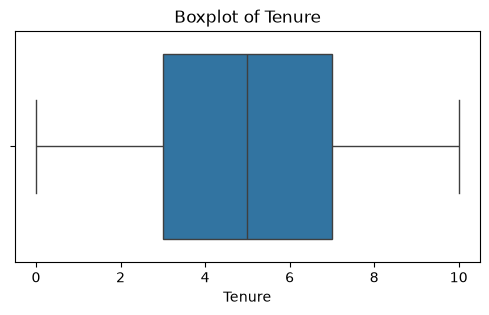

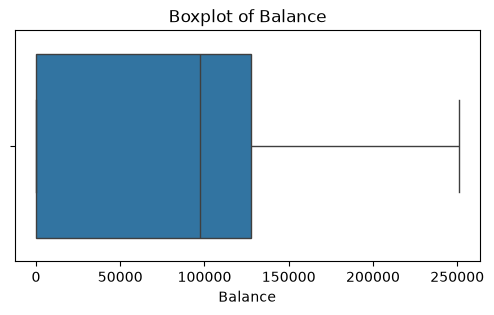

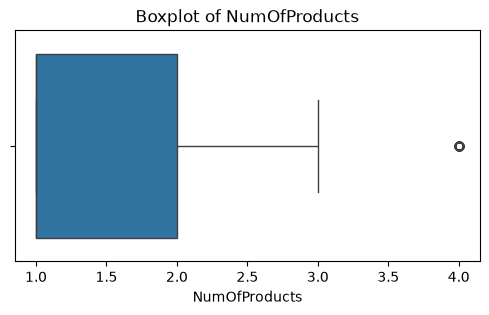

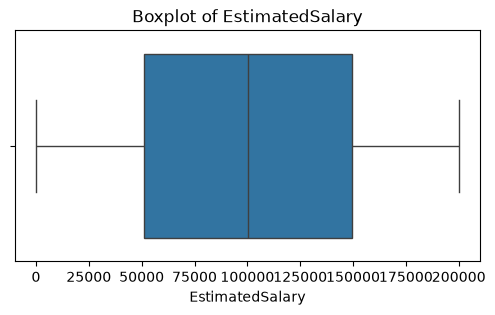

In [6]:
numeric_columns = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]

for column in numeric_columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

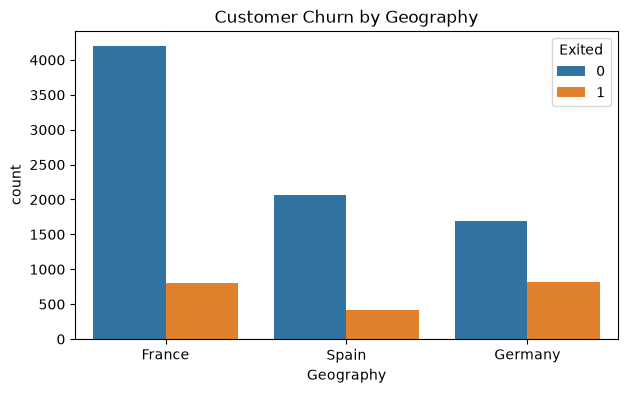

In [7]:
plt.figure(figsize=(7,4))
sns.countplot(x="Geography", hue="Exited", data=df)
plt.title("Customer Churn by Geography")
plt.show()

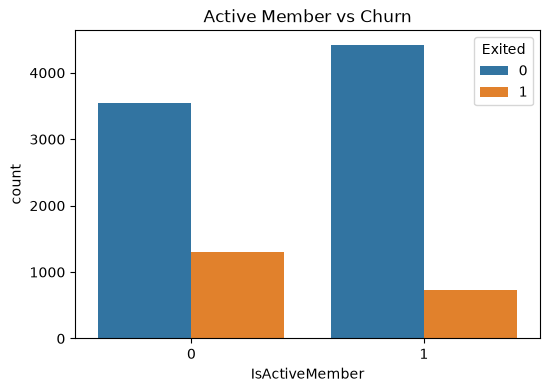

In [8]:
plt.figure(figsize=(6,4))
sns.countplot(x="IsActiveMember", hue="Exited", data=df)
plt.title("Active Member vs Churn")
plt.show()

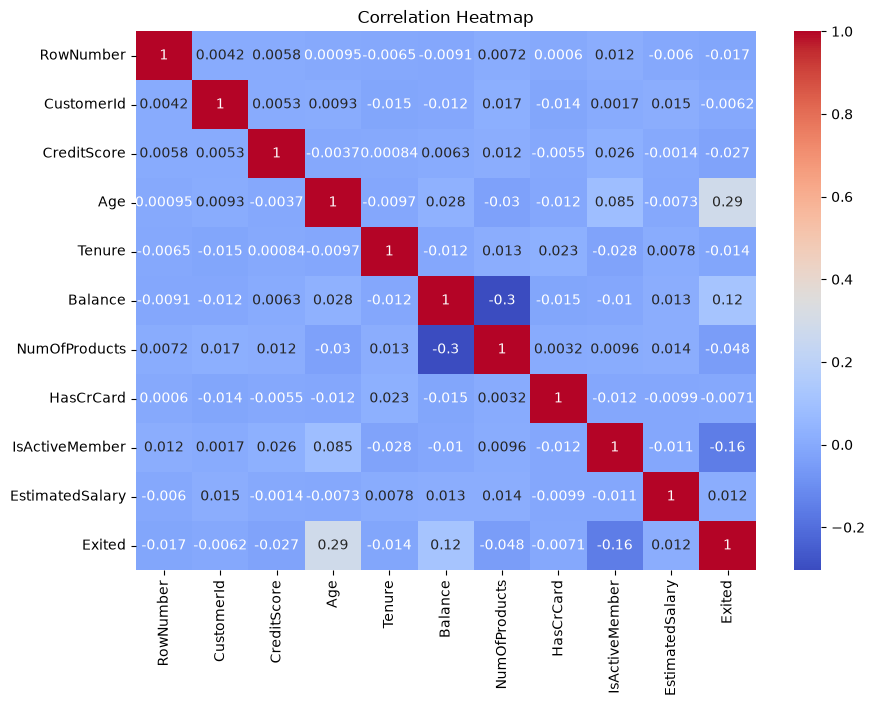

In [9]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [10]:
X = df.drop(["RowNumber", "CustomerId", "Surname", "Exited"], axis=1)
y = df["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 10)
y shape: (10000,)


In [11]:
X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True)

print(X.columns.tolist())
print(X.head())

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
   CreditScore   Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619  42.0       2       0.00              1          1   
1          608  41.0       1   83807.86              1          0   
2          502  42.0       8  159660.80              3          1   
3          699  39.0       1       0.00              2          0   
4          850  43.0       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88              False            False   
1               1        112542.58              False             True   
2               0        113931.57              False            False   
3               0         93826.63              False            False   
4               1         79084.10              F

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (8000, 11)
Testing data : (2000, 11)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training and testing data scaled.")

Training and testing data scaled.


In [14]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


In [15]:
y_pred = knn.predict(X_test_scaled)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
 
print(comparison.head(20))

    Actual  Predicted
0        0          0
1        0          0
2        0          0
3        0          0
4        0          0
5        0          0
6        0          0
7        0          0
8        0          1
9        0          0
10       1          0
11       0          0
12       0          0
13       0          0
14       0          0
15       0          0
16       0          0
17       0          0
18       1          0
19       0          0


In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy : 0.824
Precision: 0.6222222222222222
Recall   : 0.343980343980344
F1 Score : 0.4430379746835443

Classification Report
              precision    recall  f1-score   support

           0       0.85      0.95      0.90      1593
           1       0.62      0.34      0.44       407

    accuracy                           0.82      2000
   macro avg       0.74      0.65      0.67      2000
weighted avg       0.80      0.82      0.80      2000



[[1508   85]
 [ 267  140]]


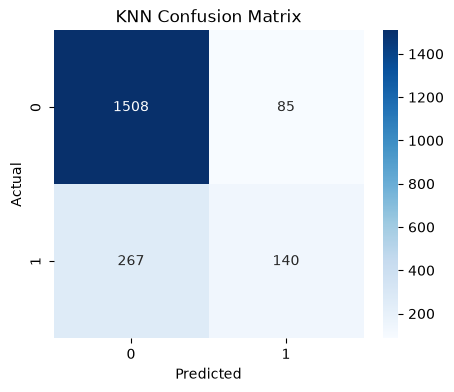

In [17]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

In [18]:
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance'}
Best CV Score: 0.8335000000000001


In [19]:
best_knn_grid = grid_search.best_estimator_
y_pred_grid = best_knn_grid.predict(X_test_scaled)

print("Test Accuracy:", accuracy_score(y_test, y_pred_grid))
print(classification_report(y_test, y_pred_grid))

Test Accuracy: 0.8375
              precision    recall  f1-score   support

           0       0.85      0.97      0.91      1593
           1       0.75      0.30      0.43       407

    accuracy                           0.84      2000
   macro avg       0.80      0.64      0.67      2000
weighted avg       0.83      0.84      0.81      2000



In [20]:
from scipy.stats import randint

param_distributions = {
    "n_neighbors": randint(1, 50),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"]
}

random_search = RandomizedSearchCV(
    KNeighborsClassifier(),
    param_distributions=param_distributions,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)

Best Parameters: {'metric': 'euclidean', 'n_neighbors': 14, 'weights': 'distance'}
Best CV Score: 0.83375


In [21]:
best_knn_random = random_search.best_estimator_
y_pred_random = best_knn_random.predict(X_test_scaled)

print("Test Accuracy:", accuracy_score(y_test, y_pred_random))
print(classification_report(y_test, y_pred_random))

Test Accuracy: 0.837
              precision    recall  f1-score   support

           0       0.85      0.97      0.90      1593
           1       0.73      0.31      0.44       407

    accuracy                           0.84      2000
   macro avg       0.79      0.64      0.67      2000
weighted avg       0.82      0.84      0.81      2000

